# 02: Grafo geográfico entre os municípios

O STGCN precisa saber quem é vizinho de quem. Aqui construímos um grafo k-NN geográfico (k = 5, kernel gaussiano) entre os 79 municípios do RJ e conferimos se ele faz sentido para a dengue.

Toda a lógica está em `src/dengue/grafo.py`. Este notebook só conta a história.

**Regra contra vazamento:** o teste de dependência espacial usa só o treino (1999 a 2012).

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from dengue import dados, grafo

ALVO = 'Taxa de Internações por Dengue'
df = dados.carregar_csv()

# Ordem dos nós: CD_MUN crescente (a mesma em todo o projeto)
coord = df.groupby('CD_MUN')[['latitude', 'longitude']].first().sort_index()
serie = df.pivot(index='Data', columns='CD_MUN', values=ALVO).sort_index(axis=1)
serie_treino = serie.loc[:'2012-12-31']
print(coord.shape, serie_treino.shape)

(79, 2) (731, 79)


## Construção do grafo

In [2]:
K = 5
dist = grafo.distancias_haversine(coord['latitude'], coord['longitude'])
adj = grafo.grafo_knn(dist, k=K)
grau = (adj > 0).sum(axis=1)
n_arestas = int((np.triu(adj, 1) > 0).sum())
print(f'{n_arestas} arestas | grau médio {grau.mean():.2f} | '
      f'grau mín {grau.min()} | grau máx {grau.max()}')

caminho = dados.RAIZ / 'data' / f'grafo_knn{K}.npy'
np.save(caminho, adj)
print('salvo em', caminho.relative_to(dados.RAIZ))

243 arestas | grau médio 6.15 | grau mín 5 | grau máx 10
salvo em data\grafo_knn5.npy


### Pergunta 1: o grafo liga municípios que de fato são próximos no mapa?

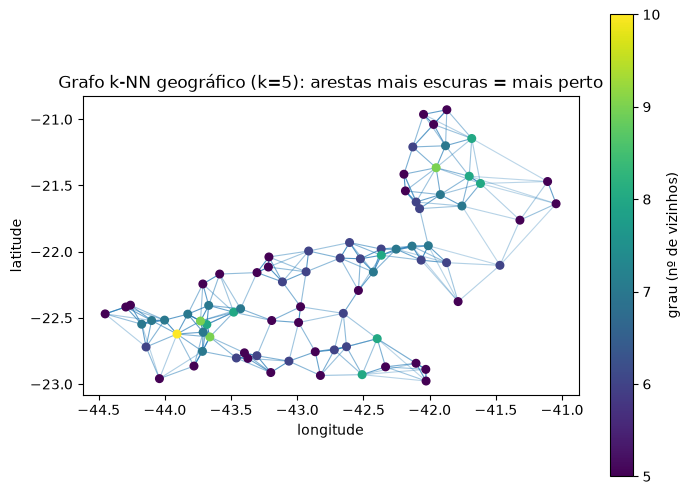

In [3]:
fig, ax = plt.subplots(figsize=(8, 6))
lat, lon = coord['latitude'].values, coord['longitude'].values
for i, j in zip(*np.nonzero(np.triu(adj, 1))):
    ax.plot([lon[i], lon[j]], [lat[i], lat[j]], color='tab:blue',
            alpha=0.3 + 0.7 * adj[i, j], lw=0.8)
pontos = ax.scatter(lon, lat, c=grau, cmap='viridis', s=30, zorder=3)
fig.colorbar(pontos, label='grau (nº de vizinhos)')
ax.set(xlabel='longitude', ylabel='latitude',
       title=f'Grafo k-NN geográfico (k={K}): arestas mais escuras = mais perto')
ax.set_aspect('equal')
plt.show()

**Conclusão:** as arestas ligam municípios próximos no mapa, e o grafo tem um único componente: de qualquer município se chega a qualquer outro, inclusive ao bloco do noroeste fluminense, que só se liga ao resto por poucas arestas. As arestas mais longas aparecem nas bordas, onde os municípios são grandes e os vizinhos estão mais longe.

### Pergunta 2: quantos vizinhos cada município tem?

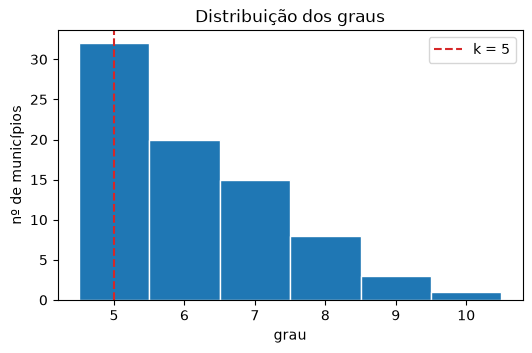

In [4]:
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.hist(grau, bins=np.arange(grau.min(), grau.max() + 2) - 0.5, edgecolor='white')
ax.axvline(K, color='tab:red', ls='--', label=f'k = {K}')
ax.set(xlabel='grau', ylabel='nº de municípios', title='Distribuição dos graus')
ax.legend()
plt.show()

**Conclusão:** todo município tem pelo menos 5 vizinhos. Alguns têm mais porque a simetrização liga i a j também quando só j escolheu i. Nenhum município fica isolado.

### Pergunta 3: municípios vizinhos têm séries de dengue mais parecidas do que pares sorteados ao acaso?

Se não tiverem, o grafo não traz informação útil para o modelo.

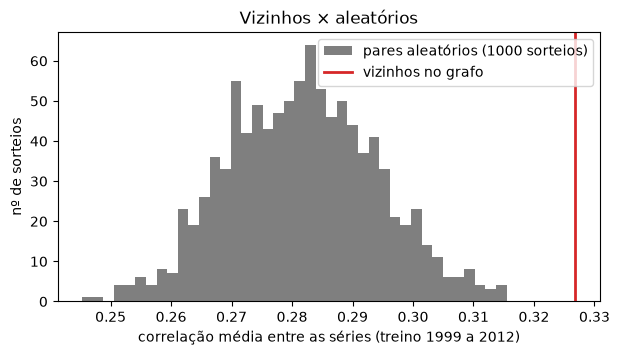

vizinhos: 0.327 | aleatórios: 0.282 | p-valor: 0.000


In [5]:
r = grafo.teste_vizinhos_aleatorios(serie_treino.values, adj, n_sorteios=1000, seed=0)

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(r['corr_aleatorios_todos'], bins=40, color='tab:gray',
        label='pares aleatórios (1000 sorteios)')
ax.axvline(r['corr_vizinhos'], color='tab:red', lw=2, label='vizinhos no grafo')
ax.set(xlabel='correlação média entre as séries (treino 1999 a 2012)',
       ylabel='nº de sorteios', title='Vizinhos × aleatórios')
ax.legend()
plt.show()
print(f"vizinhos: {r['corr_vizinhos']:.3f} | aleatórios: {r['corr_aleatorios']:.3f}"
      f" | p-valor: {r['p_valor']:.3f}")

**Conclusão:** os vizinhos são mais correlacionados que os pares aleatórios, e nenhum dos 1000 sorteios chegou ao valor dos vizinhos. A diferença é real, mas **pequena**: a dengue no RJ tem um forte componente comum ao estado inteiro (todos sobem juntos nos anos de surto). Por isso esperamos que o grafo ajude pouco além da arquitetura, e é isso que a ablação da task 17 (STGCN com A = I) vai medir.